In [409]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image
from tyssue.topology.base_topology import remove_face

from tyssue import config, Sheet, SheetGeometry, History, EventManager
from tyssue.draw import sheet_view
from tyssue.generation import three_faces_sheet
from tyssue.draw.plt_draw import plot_forces

from tyssue.dynamics import PlanarModel

from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif


import numpy as np
from tyssue.config.geometry import flat_sheet
from tyssue import Sheet, Monolayer, config, SheetGeometry
import pandas as pd

In [411]:

def one_face_sheet_array():

    Nc = 7

    points = np.array([

        # Shared junction 1
        # [ 0.0,  0.0],       # 0
        # [ 1.5,  0.0],       # 1

        # # Cell 0: upper hexagon
        # [ 2.1,  0.416667],  # 2
        # [ 1.7,  0.892857],  # 3
        # [ 0.5,  1.071429],  # 4
        # [-0.5,  0.595238],  # 5

        # # Cell 1: middle hexagon
        # [-0.55, -0.394788], # 6
        # [-0.2,  -0.971906], # 7
        # [ 1.4,  -0.971906], # 8
        # [ 2.0,  -0.455554], # 9

        # # Cell 2: lower hexagon
        # [-0.8,  -1.3560],   # 10
        # [-0.3,  -1.8498],   # 11
        # [ 1.1,  -1.9047],   # 12
        # [ 2.1,  -1.4108],   # 13






        ############################################

        [ 1.070914,  0.711508],  # 0
        [-0.041887,  1.339949],  # 1
        [-0.872656,  0.479148],  # 2
        [-1.213859, -0.862447],  # 3
        [ 0.001784, -1.152569],  # 4
        [ 1.063572, -0.625341],  # 5
    
        [ 2.964011,  0.669769],  # 6
        [ 2.112941,  1.497524],  # 7
        [ 2.260999, -1.154330],  # 8
        [ 3.255692, -0.538239],  # 9
    
        [ 0.116877, -2.510673],  # 10
        [ 0.995737, -3.088823],  # 11
        [ 2.020194, -2.555729],  # 12
    
        [-2.174725, -1.353981],  # 13
        [-2.008074, -2.724563],  # 14
        [-0.944961, -3.180640],  # 15
    
        [-2.204805,  1.028924],  # 16
        [-3.236779,  0.575119],  # 17
        [-3.181906, -0.699657],  # 18
    
        [-0.100866,  2.816503],  # 19
        [-1.002964,  2.979602],  # 20
        [-1.964590,  2.441257],  # 21
    
        [ 2.324266,  2.640716],  # 22
        [ 1.021837,  2.928893],  # 23
     

    ])

    # Six vertices per face
    faces = [
        [0, 1, 2, 3, 4, 5],       # Central cell

        [6, 7, 0, 5, 8, 9],       # Right cell
        [8, 5, 4, 10, 11, 12],    # Bottom-right cell
        [4, 3, 13, 14, 15, 10],   # Bottom-left cell
    
        [2, 16, 17, 18, 13, 3],   # Left cell
        [19, 20, 21, 16, 2, 1],   # Top-left cell
        [22, 23, 19, 1, 0, 7],    # T



       
            # [0, 1, 2, 3, 4, 5],       # Cell 0: upper hexagon
            # [0, 6, 7, 8, 9, 1],       # Cell 1: middle hexagon
            # [7, 10, 11, 12, 13, 8],   # Cell 2: lower hexagon
        ]
    

    # Generate half-edge connectivity
    edge_e_idx = []

    for face_id, face in enumerate(faces):

        for i in range(len(face)):

            srce = face[i]
            trgt = face[(i + 1) % len(face)]

            edge_e_idx.append([
                srce,
                trgt,
                face_id
            ])

    edge_e_idx = np.array(edge_e_idx, dtype=int)

    Nv = len(points)
    Ne = len(edge_e_idx)

    print("Cells:", Nc)
    print("Vertices:", Nv)
    print("Half-edges:", Ne)

    return points, edge_e_idx, (Nc, Nv, Ne)

In [413]:

from tyssue.generation.utils import make_df
import pandas as pd
import numpy as np

def one_face_sheet(zaxis=False):

    points, edge_e_idx, (Nc, Nv, Ne) = one_face_sheet_array()

    if zaxis:
        coords = ['x', 'y', 'z']
    else:
        coords = ['x', 'y']

    face_idx = pd.Index(range(Nc), name='face')
    vert_idx = pd.Index(range(Nv), name='vert')
    edge_idx = pd.Index(range(Ne), name='edge')

    specifications = flat_sheet()

    # Face dataframe
    face_df = make_df(
        index=face_idx,
        spec=specifications["face"]
    )

    # Vertex dataframe
    vert_df = make_df(
        index=vert_idx,
        spec=specifications["vert"]
    )

    # Edge dataframe
    edge_df = make_df(
        index=edge_idx,
        spec=specifications["edge"]
    )

    edge_df["srce"] = edge_e_idx[:, 0]
    edge_df["trgt"] = edge_e_idx[:, 1]
    edge_df["face"] = edge_e_idx[:, 2]

    # Assign vertex coordinates
    vert_df.loc[:, ['x', 'y']] = points

    if zaxis:
        vert_df["z"] = 0.0

    datasets = {
        "face": face_df,
        "vert": vert_df,
        "edge": edge_df
    }

    return datasets, specifications


Cells: 7
Vertices: 24
Half-edges: 42
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_024053_513533.png


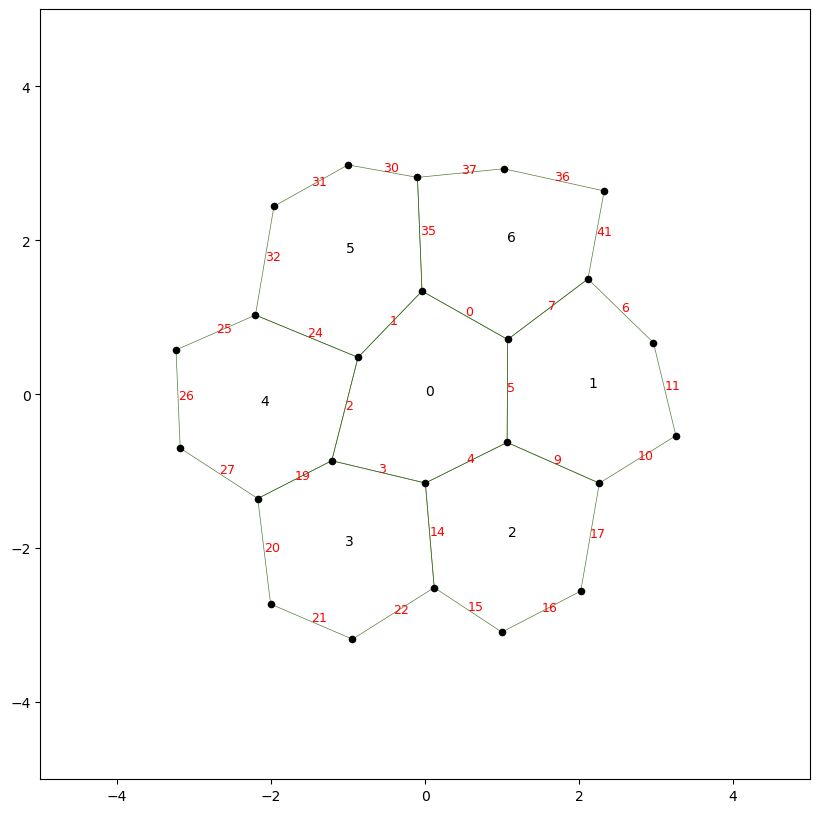

In [415]:
from tyssue.draw import sheet_view 



sheet = Sheet('1f', *one_face_sheet())



geom = SheetGeometry

geom.update_all(sheet)

fig, ax = sheet_view(sheet, xlim=(-5,20), ylim=(-5,20), figsize=(8,8))

ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
fig.set_size_inches(10, 10)

for face, data in sheet.face_df.iterrows():
    ax.text(data.x, data.y, face)


sheet.get_opposite()

for edge, data in sheet.edge_df.iterrows():
    opposite = data.opposite

    # Keep boundary edges and only one row from each shared pair
    if opposite == -1 or edge < opposite:
        x = (sheet.vert_df.loc[data.srce, "x"] +
             sheet.vert_df.loc[data.trgt, "x"]) / 2
        y = (sheet.vert_df.loc[data.srce, "y"] +
             sheet.vert_df.loc[data.trgt, "y"]) / 2
        ax.text(x, y, str(edge), color="red", fontsize=9)

In [416]:
# Get vertex coordinates
vertices = sheet.vert_df  # bu this we can get the vertices coords and store it in vertices

display(vertices)



,x,y,z,is_active,rho,height,basal_shift
vert,,,,,,,
0,1.070914,0.711508,0.0,1,0.0,-4.0,4.0
1,-0.041887,1.339949,0.0,1,0.0,-4.0,4.0
2,-0.872656,0.479148,0.0,1,0.0,-4.0,4.0
3,-1.213859,-0.862447,0.0,1,0.0,-4.0,4.0
4,0.001784,-1.152569,0.0,1,0.0,-4.0,4.0
5,1.063572,-0.625341,0.0,1,0.0,-4.0,4.0
6,2.964011,0.669769,0.0,1,0.0,-4.0,4.0
7,2.112941,1.497524,0.0,1,0.0,-4.0,4.0
8,2.260999,-1.154330,0.0,1,0.0,-4.0,4.0


In [418]:
print(sheet.vert_df[["x", "y"]]);
print(sheet.face_df[["area", "num_sides"]])
sheet.face_df

             x         y
vert                    
0     1.070914  0.711508
1    -0.041887  1.339949
2    -0.872656  0.479148
3    -1.213859 -0.862447
4     0.001784 -1.152569
5     1.063572 -0.625341
6     2.964011  0.669769
7     2.112941  1.497524
8     2.260999 -1.154330
9     3.255692 -0.538239
10    0.116877 -2.510673
11    0.995737 -3.088823
12    2.020194 -2.555729
13   -2.174725 -1.353981
14   -2.008074 -2.724563
15   -0.944961 -3.180640
16   -2.204805  1.028924
17   -3.236779  0.575119
18   -3.181906 -0.699657
19   -0.100866  2.816503
20   -1.002964  2.979602
21   -1.964590  2.441257
22    2.324266  2.640716
23    1.021837  2.928893
          area  num_sides
face                     
0     4.000000          6
1     4.000000          6
2     3.999999          6
3     4.000000          6
4     4.000000          6
5     4.000000          6
6     4.000001          6


,x,y,z,num_sides,area,perimeter,is_alive,id,height,rho,vol
face,,,,,,,,,,,
0,0.001311,-0.018292,0.0,6,4.000000,7.630738,1,0,-4.0,0.0,-16.000002
1,2.121355,0.093482,0.0,6,4.000000,7.551155,1,0,-4.0,0.0,-15.999998
2,1.076527,-1.847911,0.0,6,3.999999,7.486294,1,0,-4.0,0.0,-15.999997
3,-1.037160,-1.964146,0.0,6,4.000000,7.485066,1,0,-4.0,0.0,-16.000000
4,-2.147455,-0.138816,0.0,6,4.000000,7.509097,1,0,-4.0,0.0,-15.999999
5,-1.031295,1.847564,0.0,6,4.000000,7.566578,1,0,-4.0,0.0,-16.000001
6,1.064534,1.989182,0.0,6,4.000001,7.685764,1,0,-4.0,0.0,-16.000005


In [421]:
sheet.face_df

,x,y,z,num_sides,area,perimeter,is_alive,id,height,rho,vol
face,,,,,,,,,,,
0,0.001311,-0.018292,0.0,6,4.000000,7.630738,1,0,-4.0,0.0,-16.000002
1,2.121355,0.093482,0.0,6,4.000000,7.551155,1,0,-4.0,0.0,-15.999998
2,1.076527,-1.847911,0.0,6,3.999999,7.486294,1,0,-4.0,0.0,-15.999997
3,-1.037160,-1.964146,0.0,6,4.000000,7.485066,1,0,-4.0,0.0,-16.000000
4,-2.147455,-0.138816,0.0,6,4.000000,7.509097,1,0,-4.0,0.0,-15.999999
5,-1.031295,1.847564,0.0,6,4.000000,7.566578,1,0,-4.0,0.0,-16.000001
6,1.064534,1.989182,0.0,6,4.000001,7.685764,1,0,-4.0,0.0,-16.000005


In [423]:



valid_faces = sheet.face_df.index[sheet.face_df["area"] > 1e-12] # condition for a valid face

face_id = []

for faces in valid_faces:
    face_id.append(faces)
    
# print("No of valid face :", face_id)

# face_id = valid_faces[0]

# face_id = valid_faces[1]
# For this face, get its boundary's edge IDs and source vertex IDs

for ids in face_id:
    
    boundary = sheet.get_orbits("face", "srce").loc[ids]


    print("Face:", ids) # print face id
    print("Boundary edge IDs:", list(boundary.index)) # print edge id 
    print("Boundary vertex IDs:", list(boundary.values)) # print vertex id
    
    print(sheet.edge_df.loc[boundary.index, ["srce", "trgt", "length"]]) #calculating length by Euler distance           
    print(sheet.vert_df.loc[boundary.values, ["x", "y"]])

Face: 0
Boundary edge IDs: [0, 1, 2, 3, 4, 5]
Boundary vertex IDs: [0, 1, 2, 3, 4, 5]
      srce  trgt    length
edge                      
0        0     1  1.277992
1        1     2  1.196309
2        2     3  1.384304
3        3     4  1.249783
4        4     5  1.185480
5        5     0  1.336869
             x         y
vert                    
0     1.070914  0.711508
1    -0.041887  1.339949
2    -0.872656  0.479148
3    -1.213859 -0.862447
4     0.001784 -1.152569
5     1.063572 -0.625341
Face: 1
Boundary edge IDs: [6, 7, 8, 9, 10, 11]
Boundary vertex IDs: [6, 7, 0, 5, 8, 9]
      srce  trgt    length
edge                      
6        6     7  1.187223
7        7     0  1.305236
8        0     5  1.336869
9        5     8  1.309069
10       8     9  1.170035
11       9     6  1.242723
             x         y
vert                    
6     2.964011  0.669769
7     2.112941  1.497524
0     1.070914  0.711508
5     1.063572 -0.625341
8     2.260999 -1.154330
9     3.255692 -0.5

In [425]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

          area  perimeter  num_sides
face                                
0     4.000000   7.630738          6
1     4.000000   7.551155          6
2     3.999999   7.486294          6
3     4.000000   7.485066          6
4     4.000000   7.509097          6
5     4.000000   7.566578          6
6     4.000001   7.685764          6
7.685763767748113


In [427]:
for ids in face_id:
    
    boundary = sheet.get_orbits("face", "srce").loc[ids]

    vertex_ids = boundary.values # boundary.values gives the vertex IDs, and ["x", "y"] selects their coordinate
    coordinates = sheet.vert_df.loc[vertex_ids, ["x", "y"]] # .loc[rows, columns]
    display(coordinates)

,x,y
vert,,
0,1.070914,0.711508
1,-0.041887,1.339949
2,-0.872656,0.479148
3,-1.213859,-0.862447
4,0.001784,-1.152569
5,1.063572,-0.625341


,x,y
vert,,
6,2.964011,0.669769
7,2.112941,1.497524
0,1.070914,0.711508
5,1.063572,-0.625341
8,2.260999,-1.154330
9,3.255692,-0.538239


,x,y
vert,,
8,2.260999,-1.154330
5,1.063572,-0.625341
4,0.001784,-1.152569
10,0.116877,-2.510673
11,0.995737,-3.088823
12,2.020194,-2.555729


,x,y
vert,,
4,0.001784,-1.152569
3,-1.213859,-0.862447
13,-2.174725,-1.353981
14,-2.008074,-2.724563
15,-0.944961,-3.180640
10,0.116877,-2.510673


,x,y
vert,,
2,-0.872656,0.479148
16,-2.204805,1.028924
17,-3.236779,0.575119
18,-3.181906,-0.699657
13,-2.174725,-1.353981
3,-1.213859,-0.862447


,x,y
vert,,
19,-0.100866,2.816503
20,-1.002964,2.979602
21,-1.964590,2.441257
16,-2.204805,1.028924
2,-0.872656,0.479148
1,-0.041887,1.339949


,x,y
vert,,
22,2.324266,2.640716
23,1.021837,2.928893
19,-0.100866,2.816503
1,-0.041887,1.339949
0,1.070914,0.711508
7,2.112941,1.497524


In [429]:
from tyssue.dynamics import effectors, model_factory

area_model = model_factory([
    effectors.FaceAreaElasticity,
    effectors.LineTension
    # effectors.PerimeterElasticity
])

sheet.update_specs(area_model.specs, reset=True)

# Area energy parameters
### Pandas warns because chained indexing (["column"].iloc[]) may modify a temporary view rather than the original DataFrame. ###
# sheet.face_df["area_elasticity"].iloc[0] = 1.0
# sheet.face_df["area_elasticity"].iloc[0] = 1.0

# sheet.face_df["prefered_area"].iloc[0] = 8.0
# sheet.face_df["prefered_area"].iloc[1] = 8.0

# Area elasticity for both faces
sheet.face_df["area_elasticity"] = 1.0

# Preferred area for both faces
sheet.face_df.loc[0, "prefered_area"] = 8.0
sheet.face_df.loc[1, "prefered_area"] = 6.0
sheet.face_df.loc[2, "prefered_area"] = 8.0
sheet.face_df.loc[3, "prefered_area"] = 14.0
sheet.face_df.loc[4, "prefered_area"] = 10.0
sheet.face_df.loc[5, "prefered_area"] = 9.0
sheet.face_df.loc[6, "prefered_area"] = 8.0
# target_area = sheet.face_df["prefered_area"].iloc[0]

# line tension affector value
sheet.edge_df["line_tension"] = 0.01

# Perimeter energy parameters
# sheet.face_df["perimeter_elasticity"] = 1.0
# sheet.face_df["prefered_perimeter"] = 6 * np.sqrt(4 * target_area/ (3 * np.sqrt(3)))
# sheet.face_df["prefered_perimeter"] = 6.0 # this gives a regular hexagon shape 


geom.update_all(sheet)
# print(target_area)

Reseting column is_alive of the face dataset with new specs
Reseting column area of the face dataset with new specs
Reseting column sub_area of the edge dataset with new specs
Reseting column is_active of the edge dataset with new specs


In [431]:
import numpy as np

grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2 + grad_E["gz"]**2)

print(grad_E[["gx", "gy", "gz", "magnitude"]])

area_model.specs

            gx         gy   gz  magnitude
srce                                     
0    -2.122085   1.048428  0.0   2.366949
1    -1.170042   0.388016  0.0   1.232702
2    -2.042120   0.089194  0.0   2.044067
3    -1.232183  -5.230274  0.0   5.373457
4    -4.944751  -3.989013  0.0   6.353172
5    -1.866083  -1.191597  0.0   2.214084
6    -2.033353  -1.141377  0.0   2.331794
7    -3.896664   0.618197  0.0   3.945397
8    -3.942136   0.277130  0.0   3.951865
9    -1.818675   0.700785  0.0   1.949020
10   -6.266950   6.717083  0.0   9.186614
11    0.089854   3.801579  0.0   3.802640
12   -3.865398   2.527905  0.0   4.618615
13    9.793637   1.930752  0.0   9.982140
14    9.129303   6.145828  0.0  11.005243
15   -1.069084  10.620116  0.0  10.673790
16    4.611854  -4.361636  0.0   6.347682
17    5.180951  -2.928321  0.0   5.951245
18    5.783322   3.183891  0.0   6.601816
19   -0.921699  -4.521535  0.0   4.614522
20    0.937558  -4.655978  0.0   4.749436
21    4.873170  -3.002116  0.0   5

{'cell': {},
 'face': {'is_alive': 1,
  'area': 1.0,
  'area_elasticity': 1.0,
  'prefered_area': 1.0},
 'edge': {'sub_area': 0.16666666666666666,
  'is_active': 1,
  'line_tension': 1.0},
 'vert': {},
 'settings': {'nrj_norm_factor': 1.0}}

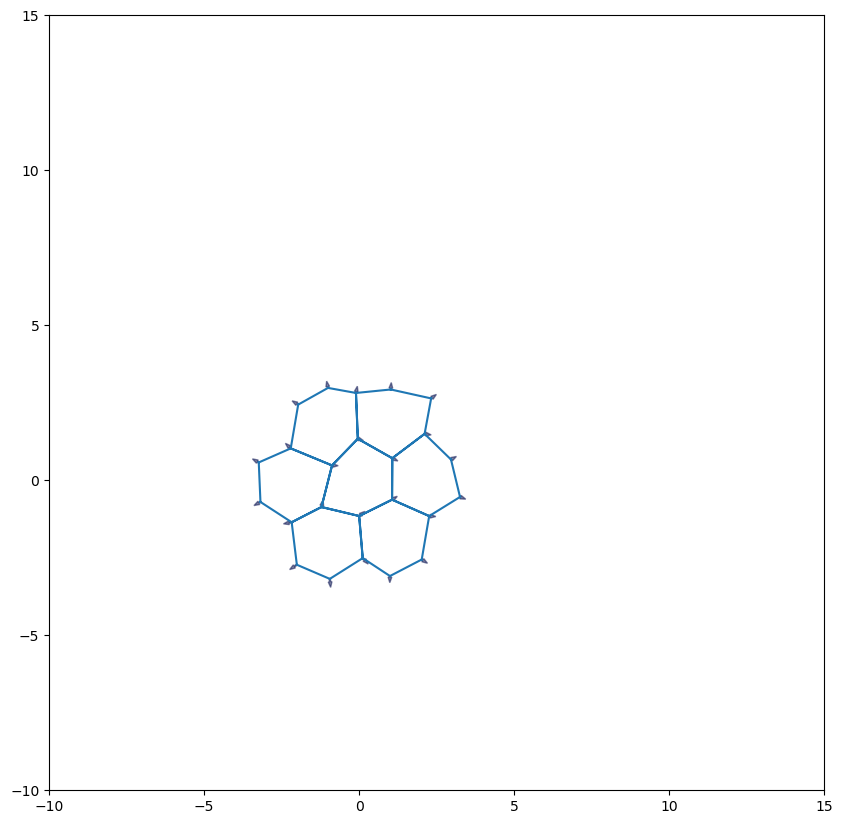

In [433]:
from tyssue.draw.plt_draw import plot_forces


fig, ax = plot_forces(sheet, geom, area_model, ['x', 'y'], scaling=0.009)
ax.set_xlim(-10, 15)
ax.set_ylim(-10, 15)

fig.set_size_inches(10, 12)

Successfull gradient descent?  True
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_024028_557563.png


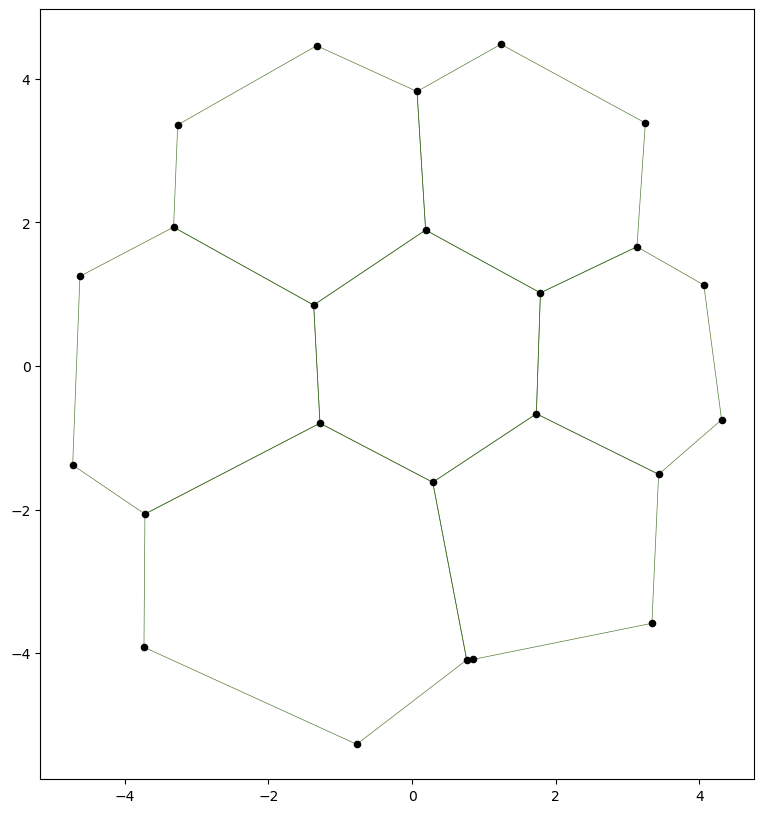

In [407]:
from tyssue.solvers import QSSolver

solver = QSSolver()
res = solver.find_energy_min(sheet, geom, area_model)

print("Successfull gradient descent? ", res['success'])
fig, ax = sheet_view(sheet)

fig.set_size_inches(10, 10)
ax.set_aspect('equal')

In [435]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

          area  perimeter  num_sides
face                                
0     4.000000   7.630738          6
1     4.000000   7.551155          6
2     3.999999   7.486294          6
3     4.000000   7.485066          6
4     4.000000   7.509097          6
5     4.000000   7.566578          6
6     4.000001   7.685764          6
7.685763767748113


In [317]:
# Assign viscosity to every vertex
sheet.vert_df["viscosity"] = 10.0

from tyssue.solvers.viscous import EulerSolver


solver = EulerSolver(sheet, geom, area_model, auto_reconnect=True)

In [319]:
import numpy as np
import time
from tyssue.solvers.viscous import EulerSolver
# from pkg_resources import Requirement

# import winsound
# from win10toast import ToastNotifier

# sheet.vert_df["viscosity"] = 10.0
# solver = EulerSolver(sheet, geom, area_model)

# import warnings

# warnings.filterwarnings("ignore", category=FutureWarning)

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

dt = 0.01
chunk_steps = 20
max_chunks = 1000
tolerance = 1e-4


times = []

gx_history = {vid: [] for vid in vertex_ids}
gy_history = {vid: [] for vid in vertex_ids}

# -------- PLOT SETTINGS --------

# X-axis range (simulation time)
x_min = 0
x_max = 100

# Y-axis range for gradient X
gx_min = -10
gx_max = 10

# Y-axis range for gradient Y
gy_min = -10
gy_max = 10


# Tick intervals (unit length)
x_tick = 10
gx_tick = 2
gy_tick = 2



energy_history = []
area_energy_history = []
line_energy_history = []
junction_length_history = []

# Update geometry before calculating initial energy
geom.update_all(sheet)

# # Initial area energy
# initial_area_energy = 0.5 * (sheet.face_df["area_elasticity"] * (sheet.face_df["area"] - sheet.face_df["prefered_area"])**2).sum()

# # Initial line-tension energy
# initial_line_energy = 0.5 * (sheet.edge_df["line_tension"] * sheet.edge_df["length"]).sum()

# initial_total_energy = initial_area_energy + initial_line_energy


start = time.perf_counter()


times = []
gx_history = {vid: [] for vid in vertex_ids}
gy_history = {vid: [] for vid in vertex_ids}


energy_history = []
# toaster = ToastNotifier()


# try: 
for chunk in range(max_chunks):
    # Advance the model by a chunk of time
    tf = (chunk + 1) * chunk_steps * dt
    solver.solve(tf=tf, dt=dt)

    grad = area_model.compute_gradient(sheet)
    grad_active = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()

    if not np.isfinite(grad_active).all():
        print("Simulation became numerically unstable.")
        break

    max_gradient = np.linalg.norm(grad_active, axis=1).max()


    times.append(tf)

    for vid in vertex_ids:
        gx_history[vid].append(grad.loc[vid, "gx"])
        gy_history[vid].append(grad.loc[vid, "gy"])

    ################################################################# 
    
    # geom.update_all(sheet)


    # # Area energy
    # area_energy = 0.5 * (
    #     sheet.face_df["area_elasticity"] *
    #     (sheet.face_df["area"] - sheet.face_df["prefered_area"])**2
    # ).sum()

    # # Line tension energy
    # line_energy = 0.5 * (sheet.edge_df["line_tension"] * sheet.edge_df["length"]).sum()

    # # Total energy difference
    # total_energy = area_energy + line_energy
    # delta_energy = total_energy - initial_total_energy

    # area_energy_history.append(area_energy)
    # line_energy_history.append(line_energy)
    # energy_history.append(delta_energy)

    #  # Common junction length
    # junction = sheet.edge_df[
    #     ((sheet.edge_df["srce"] == 0) & (sheet.edge_df["trgt"] == 5)) |
    #     ((sheet.edge_df["srce"] == 5) & (sheet.edge_df["trgt"] == 0))
    # ]
    
    # junction_length = (
    #     junction["length"].iloc[0] if not junction.empty else np.nan
    # )
    
    # junction_length_history.append(junction_length)
    
    #####################################################################################
    
    if chunk % 10 == 0:
        print(f"Chunk {chunk}: "f"max gradient = {max_gradient:.3e}, ")
              # f"ΔE = {delta_energy:.6f}, "
              # f"junction length = {junction_length:.6f}")

    # check convergence 
    if max_gradient < tolerance:
        print(f"Converged after {chunk + 1} chunks.")
        break

print(f"Elapsed time: {time.perf_counter() - start:.2f} seconds")



# except Exception as e:
#     print(f"Simulation error: {e}")
#     raise

# finally:
#     # Desktop notification
#     toaster.show_toast(
#         "Tyssue Simulation",
#         "Your simulation has stopped running!",
#         duration=10,
#         threaded=True
#     )




# import numpy as np

# dt = 0.0001
# max_steps = 10000
# tolerance = 1e-2

# for step in range(max_steps):
#     grad = area_model.compute_gradient(sheet)

#     grad_active = grad.loc[
#         sheet.active_verts, ["gx", "gy"]
#     ].to_numpy()

#     if not np.isfinite(grad_active).all():
#         print("Simulation became numerically unstable.")
#         break

#     max_force = np.linalg.norm(grad_active, axis=1).max()

#     if max_force < tolerance:
#         print(f"Equilibrium reached at step {step}")
#         print(f"Maximum gradient magnitude: {max_force:.3e}")
#         break

#     solver.solve(tf=(step + 1) * dt, dt=dt)

# else:
#     print("Maximum steps reached before equilibrium.")

Chunk 0: max gradient = 2.929e+01, 
Chunk 10: max gradient = 1.486e-01, 
Chunk 20: max gradient = 1.472e-02, 
Chunk 30: max gradient = 1.318e-02, 
Chunk 40: max gradient = 1.311e-02, 
Chunk 50: max gradient = 1.307e-02, 
Chunk 60: max gradient = 1.303e-02, 
Chunk 70: max gradient = 1.299e-02, 
Chunk 80: max gradient = 1.295e-02, 
Chunk 90: max gradient = 1.292e-02, 
Chunk 100: max gradient = 1.288e-02, 
Chunk 110: max gradient = 1.284e-02, 
Chunk 120: max gradient = 1.280e-02, 
Chunk 130: max gradient = 1.276e-02, 
Chunk 140: max gradient = 1.272e-02, 
Chunk 150: max gradient = 1.268e-02, 
Chunk 160: max gradient = 1.264e-02, 
Chunk 170: max gradient = 1.260e-02, 
Chunk 180: max gradient = 1.255e-02, 
Chunk 190: max gradient = 1.251e-02, 
Chunk 200: max gradient = 1.247e-02, 
Chunk 210: max gradient = 1.243e-02, 
Chunk 220: max gradient = 1.239e-02, 
Chunk 230: max gradient = 1.235e-02, 
Chunk 240: max gradient = 1.231e-02, 
Chunk 250: max gradient = 1.226e-02, 
Chunk 260: max gradient

In [377]:
from tyssue.topology.sheet_topology import type1_transition
from tyssue.solvers.viscous import EulerSolver
from tyssue import History


import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

dt = 0.01
chunk_steps = 20
max_chunks = 1000
tolerance = 1e-4

# Run one T1 on the current sheet.
# edge_id must refer to an edge in this pre-transition mesh.
edge_id = 3
type1_transition(sheet, edge_id, multiplier=6)

# Refresh geometry after the topology and vertex coordinates change.
geom.update_all(sheet)

# Start history and Euler solver from the updated mesh.
history = History(sheet)
sheet.vert_df["viscosity"] = 10.0

solver = EulerSolver(
    sheet,
    geom,
    area_model,
    history=history,
    auto_reconnect=False,  # no additional automatic T1 events
)

# Now evolve the mesh after the T1.
for chunk in range(max_chunks):
    tf = (chunk + 1) * chunk_steps * dt
    solver.solve(tf=tf, dt=dt)

    geom.update_all(sheet)
    grad = area_model.compute_gradient(sheet)
    grad_active = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()

    if not np.isfinite(grad_active).all():
        print("Simulation became numerically unstable.")
        break

    max_gradient = np.linalg.norm(grad_active, axis=1).max()
    times.append(tf)

    if chunk % 10 == 0:
        print(f"Chunk {chunk}: "f"max gradient = {max_gradient:.3e}, ")
              # f"ΔE = {delta_energy:.6f}, "
              # f"junction length = {junction_length:.6f}")

    # check convergence 
    if max_gradient < tolerance:
        print(f"Converged after {chunk + 1} chunks.")
        break

print(f"Elapsed time: {time.perf_counter() - start:.2f} seconds")

    # Keep the rest of your energy and junction-length calculations here.

Chunk 0: max gradient = 1.258e+01, 
Chunk 10: max gradient = 5.579e+00, 
Chunk 20: max gradient = 8.036e-01, 
Chunk 30: max gradient = 1.108e-01, 
Chunk 40: max gradient = 1.431e-02, 
Chunk 50: max gradient = 6.799e-03, 
Chunk 60: max gradient = 6.714e-03, 
Chunk 70: max gradient = 6.686e-03, 
Chunk 80: max gradient = 6.665e-03, 
Chunk 90: max gradient = 6.646e-03, 
Chunk 100: max gradient = 6.626e-03, 
Chunk 110: max gradient = 6.607e-03, 
Chunk 120: max gradient = 6.588e-03, 
Chunk 130: max gradient = 6.568e-03, 
Chunk 140: max gradient = 6.549e-03, 
Chunk 150: max gradient = 6.530e-03, 
Chunk 160: max gradient = 6.510e-03, 
Chunk 170: max gradient = 6.491e-03, 
Chunk 180: max gradient = 6.471e-03, 
Chunk 190: max gradient = 6.452e-03, 
Chunk 200: max gradient = 6.432e-03, 
Chunk 210: max gradient = 6.412e-03, 
Chunk 220: max gradient = 6.393e-03, 
Chunk 230: max gradient = 6.373e-03, 
Chunk 240: max gradient = 6.353e-03, 
Chunk 250: max gradient = 6.333e-03, 
Chunk 260: max gradient

In [379]:
create_gif(solver.history, "sheet3.gif", num_frames=200)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023740_504356.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023740_726102.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023740_982763.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023741_223417.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023741_427870.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023741_612974.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023741_921723.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023742_172094.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023742_419703.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023742_636980.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023742_859711.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023743_127615.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_023743_371019.png
Plot saved: C:\Users\Arya

'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'

In [187]:
#-----------Printing junction lengths-------------#

geom.update_all(sheet)
sheet.get_opposite()

junctions = sheet.edge_df[
    (sheet.edge_df["opposite"] > -1)
    & (sheet.edge_df.index < sheet.edge_df["opposite"])
]

for edge, row in junctions.iterrows():
    print(
        f"Edge {edge}: vertices {int(row['srce'])}–{int(row['trgt'])}, "
        f"length = {row['length']:.6f}"
    )

Edge 0: vertices 0–1, length = 0.890041
Edge 1: vertices 1–2, length = 0.891297
Edge 2: vertices 2–3, length = 0.879379
Edge 3: vertices 3–4, length = 1.874595
Edge 4: vertices 4–5, length = 0.761975
Edge 5: vertices 5–0, length = 1.295139
Edge 7: vertices 7–0, length = 2.262096
Edge 9: vertices 5–8, length = 1.693187
Edge 14: vertices 4–10, length = 2.614154
Edge 19: vertices 3–13, length = 2.864868
Edge 24: vertices 2–16, length = 3.139131
Edge 35: vertices 1–19, length = 2.814999


In [441]:




# --------------------- T-1 Transition Block w/o setting interior edges or junction length after splitting -------------------------#






import numpy as np
import time
import warnings

from tyssue import History
from tyssue.solvers.viscous import EulerSolver
from tyssue.draw.plt_draw import create_gif

warnings.filterwarnings("ignore", category=FutureWarning)

# Assumes these already exist:
#   sheet, geom, area_model
# Start with a fresh sheet from before any manual type1_transition call.

dt = 0.01
chunk_steps = 20
max_chunks = 5000
tolerance = 1e-4

# Set this in the same coordinate units as your sheet.
# Choose a value below the junction length you want to shrink.
sheet.settings["threshold_length"] = 1.1
sheet.vert_df["viscosity"] = 1.0

# Save one history frame per Euler step.
history = History(sheet, save_every=dt, dt=dt)

# Track whether the solver has changed the topology.
topology_changed = [False]

def on_topo_change(eptm):
    topology_changed[0] = True
    print("Topology changed: Tyssue performed a reconnection.")

# This is where automatic T1 handling is enabled.
solver = EulerSolver(
    sheet,
    geom,
    area_model,
    history=history,
    auto_reconnect=True,
)

# -------- PLOT SETTINGS --------

x_min = 0
x_max = 100

gx_min = -10
gx_max = 10

gy_min = -10
gy_max = 10

x_tick = 10
gx_tick = 2
gy_tick = 2

# -------- HISTORY ARRAYS --------

times = []

# Each item is a Series indexed by the vertex IDs at that time.
# This avoids assuming vertex IDs stay fixed through a T1.
gx_history = []
gy_history = []

energy_history = []
area_energy_history = []
line_energy_history = []
junction_length_history = []

# Update geometry before calculating initial energy.
geom.update_all(sheet)

initial_area_energy = 0.5 * (
    sheet.face_df["area_elasticity"]
    * (sheet.face_df["area"] - sheet.face_df["prefered_area"]) ** 2
).sum()

initial_line_energy = 0.5 * (
    sheet.edge_df["line_tension"] * sheet.edge_df["length"]
).sum()

initial_total_energy = initial_area_energy + initial_line_energy

start = time.perf_counter()

for chunk in range(max_chunks):
    # Advance to the end of this chunk.
    tf = (chunk + 1) * chunk_steps * dt

    solver.solve(
        tf=tf,
        dt=dt,
        on_topo_change=on_topo_change,
        topo_change_args=(sheet,),
    )

    # Recalculate geometry before reading lengths and energies.
    geom.update_all(sheet)

    # Compute gradients using the current mesh and its current vertex IDs.
    grad = area_model.compute_gradient(sheet)
    grad_active = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()

    if not np.isfinite(grad_active).all():
        print("Simulation became numerically unstable.")
        break

    max_gradient = np.linalg.norm(grad_active, axis=1).max()

    times.append(tf)
    gx_history.append(grad["gx"].copy())
    gy_history.append(grad["gy"].copy())

    # Area energy
    area_energy = 0.5 * (
        sheet.face_df["area_elasticity"]
        * (sheet.face_df["area"] - sheet.face_df["prefered_area"]) ** 2
    ).sum()

    # Line-tension energy
    line_energy = 0.5 * (
        sheet.edge_df["line_tension"] * sheet.edge_df["length"]
    ).sum()

    total_energy = area_energy + line_energy
    delta_energy = total_energy - initial_total_energy

    area_energy_history.append(area_energy)
    line_energy_history.append(line_energy)
    energy_history.append(delta_energy)

    # Track the 0–5 junction only until a topology change.
    # After T1, vertex IDs may refer to different vertices.
    if topology_changed[0]:
        junction_length = np.nan
    else:
        junction = sheet.edge_df[
            (
                (sheet.edge_df["srce"] == 0)
                & (sheet.edge_df["trgt"] == 5)
            )
            | (
                (sheet.edge_df["srce"] == 5)
                & (sheet.edge_df["trgt"] == 0)
            )
        ]
        junction_length = (
            junction["length"].iloc[0] if not junction.empty else np.nan
        )

    junction_length_history.append(junction_length)

    if chunk % 10 == 0:
        print(
            f"Chunk {chunk}: "
            f"max gradient = {max_gradient:.3e}, "
            f"ΔE = {delta_energy:.6f}, "
            f"junction length = {junction_length:.6f}"
        )

    if max_gradient < tolerance:
        print(f"Converged after {chunk + 1} chunks.")
        break

print(f"Elapsed time: {time.perf_counter() - start:.2f} seconds")

# Create an animation from the recorded simulation.
create_gif(
    history,
    "t1_dynamics.gif",
    # num_frames=min(120, len(history)),
    num_frames= 500,
)

Topology changed: Tyssue performed a reconnection.
Topology changed: Tyssue performed a reconnection.
Topology changed: Tyssue performed a reconnection.
Chunk 0: max gradient = 3.875e+00, ΔE = -92.938916, junction length = nan
Topology changed: Tyssue performed a reconnection.
Converged after 8 chunks.
Elapsed time: 9.78 seconds
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044833_450043.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044833_673279.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044833_916687.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044834_129357.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044834_379591.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044834_632596.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044834_882202.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044835_142356.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261109_044835_34499

'C:\\Users\\Aryan\\tyssue Simulations\\t1_dynamics.gif'

In [375]:
print(sheet.face_df.loc[face_id, ["area", "perimeter", "num_sides"]])
print(sheet.edge_df.loc[boundary.index, "length"].sum())

           area  perimeter  num_sides
face                                 
0      7.999918  10.619828          6
1      9.999950  11.867193          6
2      6.999940  10.120493          6
3     13.999966  14.063700          6
4      9.999957  11.893809          6
5      8.999948  11.308618          6
6      7.999945  10.683900          6
10.683899604949817


In [190]:
grad_E = area_model.compute_gradient(sheet)

grad_E["magnitude"] = np.sqrt(grad_E["gx"]**2 + grad_E["gy"]**2 + grad_E["gz"]**2)

print(grad_E[["gx", "gy", "gz", "magnitude"]])

            gx        gy   gz  magnitude
srce                                    
0     0.000710 -0.003286  0.0   0.003362
1     0.000085  0.003602  0.0   0.003603
2     0.007034 -0.003301  0.0   0.007770
3    -0.004372 -0.002416  0.0   0.004995
4    -0.000820  0.011196  0.0   0.011226
5    -0.004772 -0.007590  0.0   0.008965
6    -0.002818 -0.000653  0.0   0.002893
7     0.000640  0.000718  0.0   0.000962
8    -0.001536 -0.000243  0.0   0.001555
9    -0.001811  0.001005  0.0   0.002072
10   -0.006788 -0.003637  0.0   0.007701
11   -0.001555  0.001415  0.0   0.002103
12   -0.003300  0.003332  0.0   0.004690
13   -0.001829  0.000368  0.0   0.001866
14   -0.000758  0.000341  0.0   0.000831
15   -0.000339  0.001262  0.0   0.001307
16   -0.000813  0.000140  0.0   0.000825
17    0.000299  0.000679  0.0   0.000741
18    0.001123 -0.000085  0.0   0.001126
19   -0.000337  0.002880  0.0   0.002900
20    0.000554 -0.001695  0.0   0.001783
21    0.000597 -0.000914  0.0   0.001092
22   -0.000237 -

In [189]:
create_gif(solver.history, "sheet3.gif", num_frames=500)

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004055_525263.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004055_773757.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004055_987832.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004056_352840.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004056_588716.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004056_907400.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004057_120499.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004057_359163.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004057_562235.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004057_789836.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004058_021516.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004058_259448.png
Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_004058_465862.png
Plot saved: C:\Users\Arya

'C:\\Users\\Aryan\\tyssue Simulations\\sheet3.gif'

Plot saved: C:\Users\Aryan\Tyssue_outputs\sheet_20261110_024142_793760.png


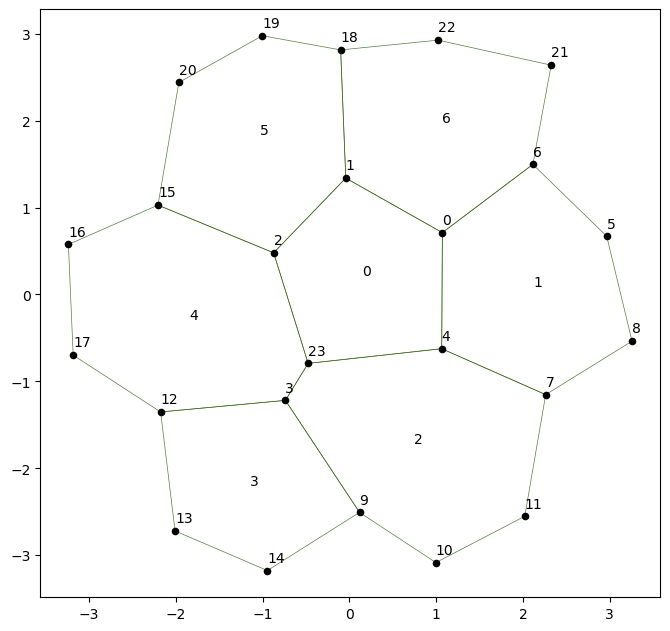

In [437]:
from tyssue.topology.sheet_topology import type1_transition
type1_transition(sheet, 3, multiplier=5)
sheet.reset_index()

geom.update_all(sheet)

fig, ax = sheet_view(sheet)
fig.set_size_inches(8, 8)
for face, data in sheet.face_df.iterrows():
    ax.text(data.x, data.y, face)

for vert, data in sheet.vert_df.iterrows():
    ax.text(data.x, data.y+0.1, vert)



In [ ]:
from tyssue.topology.sheet_topology import type1_transition

T1_MULTIPLIER = 2.0  # new edge starts at 2 × threshold_length

solver = EulerSolver(
    sheet,
    geom,
    area_model,
    history=history,
    auto_reconnect=False,
)

In [ ]:
sheet.get_opposite()
interior = sheet.edge_df[sheet.edge_df["opposite"] > -1]

if not interior.empty:
    edge = interior["length"].idxmin()

    if sheet.edge_df.loc[edge, "length"] < sheet.settings["threshold_length"]:
        type1_transition(sheet, edge, multiplier=T1_MULTIPLIER)
        geom.update_all(sheet)

        # The vertex count may have changed, so recreate the solver.
        solver = EulerSolver(
            sheet,
            geom,
            area_model,
            history=history,
            auto_reconnect=False,
        )



        for chunk in range(max_chunks):
            # Advance the model by a chunk of time
            tf = (chunk + 1) * chunk_steps * dt
            solver.solve(tf=tf, dt=dt)
        
            grad = area_model.compute_gradient(sheet)
            grad_active = grad.loc[sheet.active_verts, ["gx", "gy"]].to_numpy()
        
            if not np.isfinite(grad_active).all():
                print("Simulation became numerically unstable.")
                break
        
            max_gradient = np.linalg.norm(grad_active, axis=1).max()
        
        
            times.append(tf)

In [ ]:
def calculate_total_energy(sheet, geom):

    geom.update_all(sheet)

    # Area elasticity energy
    area_energy = 0.5 * (
        sheet.face_df["area_elasticity"] *
        (sheet.face_df["area"] -
         sheet.face_df["prefered_area"])**2
    ).sum()

    # Line tension energy
    line_energy = 0.5 * (
        sheet.edge_df["line_tension"] *
        sheet.edge_df["length"]
    ).sum()

    total_energy = area_energy + line_energy

    return area_energy, line_energy, total_energy

In [ ]:
energy_history = []
area_energy_history = []
line_energy_history = []
junction_length_history = []

# Initial energy
initial_area_energy, initial_line_energy, initial_total_energy = (
    calculate_total_energy(sheet, geom)
)

print("Initial total energy:", initial_total_energy)

In [ ]:
def calculate_junction_length(sheet, v1, v2):

    edges = sheet.edge_df

    junction = edges[
        ((edges["srce"] == v1) & (edges["trgt"] == v2)) |
        ((edges["srce"] == v2) & (edges["trgt"] == v1))
    ]

    if junction.empty:
        raise ValueError("Common junction not found.")

    return junction["length"].iloc[0]

In [ ]:
area_energy, line_energy, total_energy = (
    calculate_total_energy(sheet, geom)
)

# Energy difference relative to initial state
delta_energy = total_energy - initial_total_energy

area_energy_history.append(area_energy)
line_energy_history.append(line_energy)
energy_history.append(delta_energy)

# Common junction length
junction_length = calculate_junction_length(sheet, v1, v2)

junction_length_history.append(junction_length)